# 单次测试：Udeco2 / Udeco3

选择 **PPG_sensor_env** 内核，修改下面的 `SENSOR_FILE`，然后从上到下运行。
复用同目录 `udeco_analysis.py` 的 `load_udeco_sample`，显示经过序号修复、异常值插值和标定计算的两路 Udeco，未进行状态分类或中值滤波。

- 数据来自一份 `_sensor.csv`，标定来自 `DATA_ROOT/ck.mat`。
- 两图共享时间轴；点击图中工具栏的放大镜后拖框缩放，手形按钮平移，Home 恢复全貌。
- 要切换测试，修改参数后重跑“参数”“读取”“绘图”三个代码单元。

In [9]:
from pathlib import Path
import os

%matplotlib widget
import matplotlib.pyplot as plt
from udeco_analysis import load_udeco_sample


## 参数

默认查看 `ts_write_1_sensor.csv`。`TIME_RANGE_S=None` 显示全程，也可改成 `(30, 60)`。
协议采样率为 100 Hz；时间单位为秒。请从本 notebook 所在目录启动 Jupyter，以便导入同目录模块。

In [10]:
DATA_ROOT = Path(os.environ.get("UDECO_DATA_ROOT", r"D:\MHLcode\subject_data"))
SENSOR_FILE = DATA_ROOT / "cgx" / "cgx_rope_1_sensor.csv"
FS_HZ = 100
TIME_RANGE_S = None  # 例如 (30, 60)，也可用图中工具栏交互缩放


## 读取一次测试

Udeco2 = (Uh2 − Uc2) / (c2 − Uc2)，Udeco3 = (Uh3 − Uc3) / (c3 − Uc3)。
下方同时报告序号插值点和近零分母点，便于检查数据质量。

In [11]:
sample = None  # 读取失败时不沿用上一份数据
sample = load_udeco_sample(SENSOR_FILE, data_root=DATA_ROOT, fs=FS_HZ)
print(f"测试：{sample.sample_name}")
print(f"采样率：{sample.fs} Hz | 点数：{len(sample.time_s):,} | 时长：{len(sample.time_s) / sample.fs:.2f} s")
print(f"序号插值点：{int(sample.qc['InterpFlag'].sum())} | 近零分母点：{int(sample.qc['ud_denominator_near_zero'].sum())}")


测试：cgx_rope_1
采样率：100 Hz | 点数：20,860 | 时长：208.60 s
序号插值点：0 | 近零分母点：0


## 双通道交互图

横轴联动，纵轴分别缩放；保留全部采样点以便放大查看短时变化。
工具栏 Home 恢复全程，前进/后退按钮切换查看历史。若设置了 `TIME_RANGE_S`，初始显示该范围，Home 仍可回到全程。

如果没有交互工具栏，请确认使用 `PPG_sensor_env` 内核且已安装 `ipympl`（项目依赖已包含），重启内核后重新运行；静态 notebook 预览不支持缩放。

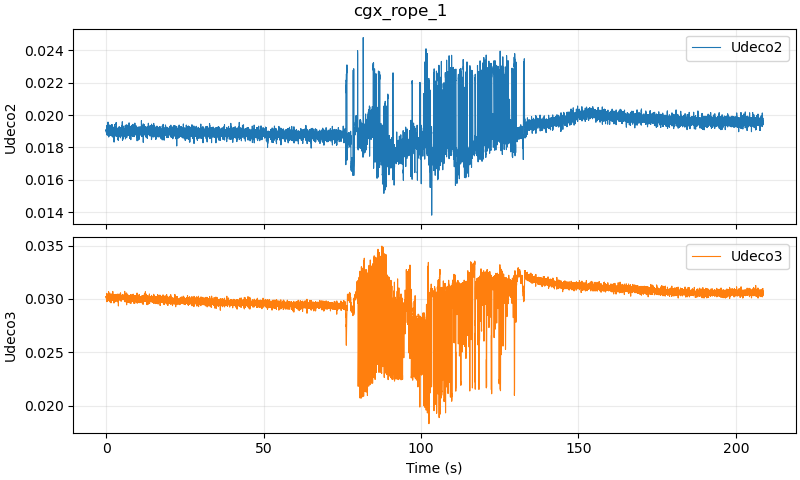

In [12]:
if sample is None:
    raise RuntimeError("请先成功运行读取单元。")

if TIME_RANGE_S is not None:
    import math
    if len(TIME_RANGE_S) != 2:
        raise ValueError("TIME_RANGE_S 应为 None 或 (开始秒, 结束秒)。")
    start, end = map(float, TIME_RANGE_S)
    if not (math.isfinite(start) and math.isfinite(end) and 0 <= start < end <= sample.time_s[-1]):
        raise ValueError(f"时间范围需满足 0 <= 开始 < 结束 <= {sample.time_s[-1]:.2f} s。")

if "fig" in globals():
    plt.close(fig)

with plt.ioff():
    fig, axes = plt.subplots(2, 1, figsize=(8, 4.8), sharex=True, layout="constrained")

for ax, values, name, color in zip(
    axes, (sample.udeco2, sample.udeco3), ("Udeco2", "Udeco3"), ("tab:blue", "tab:orange")
):
    ax.plot(sample.time_s, values, color=color, linewidth=0.8, label=name)
    ax.set_ylabel(name)
    ax.grid(True, alpha=0.25)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Time (s)")
fig.suptitle(sample.sample_name)
fig.canvas.toolbar_visible = True
fig.canvas.toolbar_position = "bottom"
fig.canvas.header_visible = False

# 将全程视图作为 Home，再应用可选初始范围。
fig.canvas.draw()
fig.canvas.toolbar.push_current()
if TIME_RANGE_S is not None:
    axes[-1].set_xlim(start, end)
    fig.canvas.toolbar.push_current()

plt.show()
